In [37]:
import os
import glob

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from PIL import Image

In [38]:
# =============================================================================
# CONFIGURATION
# =============================================================================

RESULTS_DIR = "."                                   # folder with the *_results.xlsx files
FIG_DIR     = "output"                             # output folder for all figures
LAYOUT_DIR  = os.path.join(FIG_DIR, "layouts")
VARIANT     = "BASE"                                # {Problem Variants} field of the archetype code

os.makedirs(LAYOUT_DIR, exist_ok=True)

plt.rcParams.update({
    "font.size":        10,   # generic text (annotations, text inside bars)
    "axes.titlesize":   12,   # subplot titles
    "axes.labelsize":   10,   # axis titles
    "xtick.labelsize":  10,   # x-axis tick labels
    "ytick.labelsize":  10,   # y-axis tick labels
    "legend.fontsize":  10,   # legends
    "figure.titlesize": 12,   # figure titles (suptitle)
})

In [39]:
# =============================================================================
# ARCHETYPE PILLARS
# Archetype code: {Generation}_{Topology}_{Scale}_{Variant}
# =============================================================================
ARCHETYPES = {
    #  id          generation   topology       scale           generation method
    "3G_R_S": dict(gen="3GDH",  topo="Radial", scale="Small",  method="I"),
    "3G_L_S": dict(gen="3GDH",  topo="Ring",   scale="Small",  method="I"),
    "3G_M_S": dict(gen="3GDH",  topo="Meshed", scale="Small",  method="I"),
    "3G_M_M": dict(gen="3GDH",  topo="Meshed", scale="Medium", method="II"),
    "4G_M_M": dict(gen="4GDH",  topo="Meshed", scale="Medium", method="II"),
    "5G_M_M": dict(gen="5GDHC", topo="Meshed", scale="Medium", method="II"),
    "3G_M_L": dict(gen="3GDH",  topo="Meshed", scale="Large",  method="II"),
}

CLASS_NAMES = {
    "THV": "Thermo-Hydraulic Validation",
    "TA":  "Technology Assessment",
    "CS":  "Computational Scalability",
}

CS_SERIES = {
    "topology": ["3G_R_S", "3G_L_S", "3G_M_S"],
    "size":     ["3G_M_S", "3G_M_M", "3G_M_L"],
}
BENCH_OBJECTIVES = {
    "THV": ["3G_R_S", "3G_L_S", "3G_M_S"],
    "TA":  ["3G_M_M", "4G_M_M", "5G_M_M"],
    "CS":  list(dict.fromkeys(CS_SERIES["topology"] + CS_SERIES["size"])),
}

def folder_name(aid):
    """Archetype folder / file prefix, e.g. '3G_R_S' -> '3G_R_S_BASE'."""
    return f"{aid}_{VARIANT}"

# Overview table: archetype descriptors + class membership
overview = pd.DataFrame(ARCHETYPES).T
for cls, ids in BENCH_OBJECTIVES.items():
    overview[cls] = ["✓" if a in ids else "" for a in overview.index]
overview

,gen,topo,scale,method,THV,TA,CS
3G_R_S,3GDH,Radial,Small,I,✓,,✓
3G_L_S,3GDH,Ring,Small,I,✓,,✓
3G_M_S,3GDH,Meshed,Small,I,✓,,✓
3G_M_M,3GDH,Meshed,Medium,II,,✓,✓
4G_M_M,4GDH,Meshed,Medium,II,,✓,
5G_M_M,5GDHC,Meshed,Medium,II,,✓,
3G_M_L,3GDH,Meshed,Large,II,,,✓


In [40]:
# =============================================================================
# LOAD SIMULATION RESULTS
# One Excel workbook per archetype, one sheet per variable,
# rows = timesteps (first column), columns = network elements.
# =============================================================================
LONG_FORMAT_SHEETS = {"convergence_traj"}            # sheets not indexed by timestep

def _realign_source(sheets, reference="sub_Q_W"):
    """Align the index of the 'source' sheet to the reference sheet, if needed."""
    if "source" not in sheets or reference not in sheets:
        return sheets
    src, ref_idx = sheets["source"], sheets[reference].index
    if len(src) != len(ref_idx):
        print(f"   [WARN] 'source' has {len(src)} rows vs {len(ref_idx)} in '{reference}': not realigned")
    elif not src.index.equals(ref_idx):
        sheets["source"] = src.set_axis(ref_idx).rename_axis("timestep")
        print(f"   [FIX] 'source' index realigned to '{reference}'")
    return sheets

def load_results(aid):
    """Read all sheets of an archetype workbook; index time-series sheets by timestep."""
    path = os.path.join(RESULTS_DIR, f"{folder_name(aid)}_results.xlsx")
    if not os.path.isfile(path):
        print(f"[SKIP] {aid}: {os.path.basename(path)} not found")
        return None
    sheets = pd.read_excel(path, sheet_name=None)
    for name, df in sheets.items():
        if name not in LONG_FORMAT_SHEETS:
            sheets[name] = df.rename(columns={df.columns[0]: "timestep"}).set_index("timestep")
    print(f"[OK]   {aid}: {len(sheets)} sheets")
    return _realign_source(sheets)

results = {}
for aid in ARCHETYPES:
    data = load_results(aid)
    if data is not None:
        results[aid] = data

[OK]   3G_R_S: 17 sheets
   [FIX] 'source' index realigned to 'sub_Q_W'
[OK]   3G_L_S: 17 sheets
   [FIX] 'source' index realigned to 'sub_Q_W'
[OK]   3G_M_S: 17 sheets
   [FIX] 'source' index realigned to 'sub_Q_W'
[OK]   3G_M_M: 15 sheets
   [FIX] 'source' index realigned to 'sub_Q_W'
[OK]   4G_M_M: 18 sheets
[OK]   5G_M_M: 31 sheets
[OK]   3G_M_L: 15 sheets
   [FIX] 'source' index realigned to 'sub_Q_W'


In [41]:
# =============================================================================
# NETWORKS GROUPED BY BENCHMARK OBJECTIVE
# =============================================================================
def subset(ids):
    """Results of the given archetypes, in the given order (missing ones skipped)."""
    return {a: results[a] for a in ids if a in results}

THV_NETWORKS = subset(BENCH_OBJECTIVES["THV"])
TA_NETWORKS  = subset(BENCH_OBJECTIVES["TA"])
CS_NETWORKS  = subset(BENCH_OBJECTIVES["CS"])
CS_TOPOLOGY  = subset(CS_SERIES["topology"])
CS_SIZE      = subset(CS_SERIES["size"])

for cls, nets in (("THV", THV_NETWORKS), ("TA", TA_NETWORKS), ("CS", CS_NETWORKS)):
    print(f"{cls:<4} {CLASS_NAMES[cls]:<28} -> {list(nets)}")
print(f"     CS topology series           -> {list(CS_TOPOLOGY)}")
print(f"     CS size series               -> {list(CS_SIZE)}")

THV  Thermo-Hydraulic Validation  -> ['3G_R_S', '3G_L_S', '3G_M_S']
TA   Technology Assessment        -> ['3G_M_M', '4G_M_M', '5G_M_M']
CS   Computational Scalability    -> ['3G_R_S', '3G_L_S', '3G_M_S', '3G_M_M', '3G_M_L']
     CS topology series           -> ['3G_R_S', '3G_L_S', '3G_M_S']
     CS size series               -> ['3G_M_S', '3G_M_M', '3G_M_L']


# LAYOUT

In [42]:
# =============================================================================
# NETWORK LAYOUTS — one PNG per archetype
# =============================================================================
# ---- Canvas and export ----------------------------------------------------
CANVAS_W_IN, CANVAS_H_IN = 3.0, 2.4      # drawing canvas [in]
DISPLAY_W_IN   = 0.74                    # width at which the image is shown in the paper [in]
MARGIN         = 0.05                    # relative margin around the network
EXPORT_DPI     = 600
TRANSPARENT    = True
SHOW_JUNCTIONS = True

# ---- Style (sizes refer to the displayed width) ---------------------------
LAYOUT_STYLE = {
    "pipe":       "black",
    "source":     dict(fc="blue",    ec="blue",    s=3.0,  z=6, marker="s"),
    "prosumer":   dict(fc="#FF00FF", ec="blue",    s=1.0,  z=4, marker="o"),
    "substation": dict(fc="#CCCCFF", ec="blue",    s=1.0,  z=4, marker="o"),
    "junction":   dict(fc="black",   ec="black",   s=0.25, z=3, marker="."),
}
PIPE_LW, EDGE_LW = 0.15, 0.10
FLIP_Y = {"I": True, "II": False}        # Methodology I coordinates have y pointing down

# ---- Archetype folder (nodes.csv / pipes.csv) -----------------------------
def locate_archetypes_dir(anchor=folder_name("3G_R_S"), max_up=5):
    cur = os.path.abspath(RESULTS_DIR)
    for _ in range(max_up + 1):
        hits = glob.glob(os.path.join(cur, "**", anchor, "nodes.csv"), recursive=True)
        if hits:
            return os.path.dirname(os.path.dirname(hits[0]))
        cur = os.path.dirname(cur)
    raise FileNotFoundError("Set ARCHETYPES_DIR manually (folder containing the *_BASE folders).")

ARCHETYPES_DIR = globals().get("ARCHETYPES_DIR") or locate_archetypes_dir()
print("ARCHETYPES_DIR =", ARCHETYPES_DIR)

def load_topology(aid):
    """Node positions, node types and pipe table of an archetype."""
    base  = os.path.join(ARCHETYPES_DIR, folder_name(aid))
    nodes = pd.read_csv(os.path.join(base, "nodes.csv"))
    pipes = pd.read_csv(os.path.join(base, "pipes.csv"))
    sign  = -1.0 if FLIP_Y[ARCHETYPES[aid]["method"]] else 1.0
    pos   = {r.node_id: (float(r.x_m), sign * float(r.y_m)) for r in nodes.itertuples()}
    unknown = set(nodes.node_type) - set(LAYOUT_STYLE)
    if unknown:
        print(f"   [WARN] {aid}: node types {unknown} drawn as substations")
    ntype = {r.node_id: (r.node_type if r.node_type in LAYOUT_STYLE else "substation")
             for r in nodes.itertuples()}
    return pos, ntype, pipes

def fit_limits(xs, ys):
    """Axis limits centring the network on the canvas with equal x/y scale."""
    w, h = max(max(xs) - min(xs), 1e-9), max(max(ys) - min(ys), 1e-9)
    s  = min((1 - 2 * MARGIN) * CANVAS_W_IN / w, (1 - 2 * MARGIN) * CANVAS_H_IN / h)
    cx, cy = (max(xs) + min(xs)) / 2, (max(ys) + min(ys)) / 2
    return ((cx - CANVAS_W_IN / s / 2, cx + CANVAS_W_IN / s / 2),
            (cy - CANVAS_H_IN / s / 2, cy + CANVAS_H_IN / s / 2))

def draw_layout(aid):
    """Bare network layout on the fixed canvas."""
    pos, ntype, pipes = load_topology(aid)
    k = CANVAS_W_IN / DISPLAY_W_IN               # scale factor canvas -> displayed size

    fig = plt.figure(figsize=(CANVAS_W_IN, CANVAS_H_IN))
    ax  = fig.add_axes([0, 0, 1, 1]); ax.axis("off")
    xlim, ylim = fit_limits([p[0] for p in pos.values()], [p[1] for p in pos.values()])
    ax.set_xlim(*xlim); ax.set_ylim(*ylim)

    ax.add_collection(LineCollection([(pos[r.from_node], pos[r.to_node]) for r in pipes.itertuples()],
                                     colors=LAYOUT_STYLE["pipe"], linewidths=PIPE_LW * k,
                                     capstyle="round", zorder=2))
    for kind in ("junction", "substation", "prosumer", "source"):
        if kind == "junction" and not SHOW_JUNCTIONS:
            continue
        ids = [n for n, t in ntype.items() if t == kind]
        if ids:
            st = LAYOUT_STYLE[kind]
            ax.scatter([pos[n][0] for n in ids], [pos[n][1] for n in ids], s=st["s"] * k**2,
                       marker=st["marker"], facecolor=st["fc"], edgecolor=st["ec"],
                       linewidths=EDGE_LW * k, zorder=st["z"])
    return fig

# ---- Export ---------------------------------------------------------------
LAYOUT_FILES = {}
for aid in ARCHETYPES:
    if not os.path.isdir(os.path.join(ARCHETYPES_DIR, folder_name(aid))):
        print(f"[SKIP] {aid}: folder not found")
        continue
    fig  = draw_layout(aid)
    path = os.path.join(LAYOUT_DIR, f"{aid}_layout.png")
    fig.savefig(path, dpi=EXPORT_DPI, transparent=TRANSPARENT)   # no bbox_inches: same canvas for all
    plt.close(fig)
    LAYOUT_FILES[aid] = path
    print(f"[SAVED] {aid} -> {path}")

# ---- Consistency check: identical pixel size ------------------------------
sizes = {a: Image.open(p).size for a, p in LAYOUT_FILES.items()}
assert len(set(sizes.values())) <= 1, f"Layouts do not share the same pixel size: {sizes}"
print("All layouts share the same size:", next(iter(sizes.values()), "n/a"))

ARCHETYPES_DIR = C:\Users\sara.ferrero\PycharmProjects\dhn-benchmark\archetypes_generation\archetypes
[SAVED] 3G_R_S -> output\layouts\3G_R_S_layout.png
[SAVED] 3G_L_S -> output\layouts\3G_L_S_layout.png
[SAVED] 3G_M_S -> output\layouts\3G_M_S_layout.png
[SAVED] 3G_M_M -> output\layouts\3G_M_M_layout.png
[SAVED] 4G_M_M -> output\layouts\4G_M_M_layout.png
[SAVED] 5G_M_M -> output\layouts\5G_M_M_layout.png
[SAVED] 3G_M_L -> output\layouts\3G_M_L_layout.png
All layouts share the same size: (1800, 1440)


# RESULTS

In [43]:
# =============================================================================
# COMMON TOOLS FOR THE RESULTS
# =============================================================================
import networkx as nx
import matplotlib.patheffects as pe
from matplotlib.lines import Line2D

STEP_H          = 10 / 60                     # time step [h]
STEPS_PER_DAY   = 144
RESULTS_FIG_DIR = os.path.join(FIG_DIR, "results")
os.makedirs(RESULTS_FIG_DIR, exist_ok=True)


ARCH_COLORS = {
    "3G_R_S": "#0000FFB3", "3G_L_S": "#7979FF", "3G_M_S": "#4DB0A6",     # small
    "3G_M_M": "#4DB0A6", "4G_M_M": "#9AC7BF", "5G_M_M": "#A680B8",     # medium
    "3G_M_L": "#4DB0A6",                                               # large
}
SCALE_EDGE = {
    "Small":  dict(edgecolor="none",    linewidth=0.00),
    "Medium": dict(edgecolor="#4D4D4D", linewidth=1.00),
    "Large":  dict(edgecolor="#000000", linewidth=1.25),
}
MARKER_HAIRLINE = True

LINE_W     = 2.0
LINE_ALPHA = 0.80

def arch_edge(aid):
    """Outline of bars and boxes of an archetype (by scale, as in the methodology figure)."""
    return SCALE_EDGE[ARCHETYPES[aid]["scale"]]

def arch_edges(ids):
    """Outline lists for a bar call with one bar per archetype."""
    return dict(edgecolor=[arch_edge(a)["edgecolor"] for a in ids],
                linewidth=[arch_edge(a)["linewidth"] for a in ids])

def arch_marker_edge(aid):
    """Outline of scatter markers of an archetype (keyword names of ax.scatter)."""
    e = arch_edge(aid)
    if e["linewidth"] == 0 and MARKER_HAIRLINE:
        e = dict(edgecolor="#4D4D4D", linewidth=0.4)
    return dict(edgecolors=e["edgecolor"], linewidths=e["linewidth"])

SOURCE_LABELS = {"src": "Central source", "src0": "Main source", "src1": "Auxiliary source"}

def save_fig(fig, name):
    path = os.path.join(RESULTS_FIG_DIR, f"{name}.png")
    fig.savefig(path, dpi=300, bbox_inches="tight")
    print(f"[SAVED] {path}")

# ---- Network data (nodes.csv / pipes.csv) -----------------------------------
_NET = {}
def load_network(aid):
    """nodes table, pipes table (indexed by pipe_id) and weighted graph of an archetype."""
    if aid not in _NET:
        base  = os.path.join(ARCHETYPES_DIR, folder_name(aid))
        nodes = pd.read_csv(os.path.join(base, "nodes.csv"))
        pipes = pd.read_csv(os.path.join(base, "pipes.csv")).set_index("pipe_id")
        G = nx.Graph()
        for pid, r in pipes.iterrows():
            G.add_edge(r.from_node, r.to_node, length=r.length_m, pid=pid)
        _NET[aid] = (nodes, pipes, G)
    return _NET[aid]

def reference_source(aid):
    """Node id of the reference source (first source of nodes.csv)."""
    nodes = load_network(aid)[0]
    return nodes.loc[nodes.node_type.eq("source"), "node_id"].iloc[0]

def users(aid):
    """Substations and prosumers (all heat users)."""
    nodes = load_network(aid)[0]
    return nodes.loc[nodes.node_type.isin(["substation", "prosumer"]), "node_id"].tolist()

# ---- Time series helpers ----------------------------------------------------
def source_power(aid):
    """Heat injected by the central source(s) [W], one column per source."""
    net = results[aid]
    if "src_Q_W" in net:
        return net["src_Q_W"]
    return net["source"][["Q_W"]].rename(columns={"Q_W": "src"})

def source_mdot(aid):
    net = results[aid]
    if "src_mdot_kgs" in net:
        return net["src_mdot_kgs"]
    return net["source"][["mdot_kgs"]].rename(columns={"mdot_kgs": "src"})

def prosumer_power(aid):
    """Heat injected by the prosumers [W] (zero if none)."""
    net = results[aid]
    if "pro_prod_Q_W" in net:
        return net["pro_prod_Q_W"].sum(axis=1)
    return pd.Series(0.0, index=net["sub_Q_W"].index)

def demand_power(aid):
    """Heat delivered to all users [W]."""
    net = results[aid]
    d = net["sub_Q_W"].sum(axis=1)
    if "pro_cons_Q_W" in net:
        d = d + net["pro_cons_Q_W"].sum(axis=1)
    return d

def user_supply_T(aid, prosumers=False):
    """Supply temperature at the substations [°C] (optionally also at the prosumers)."""
    net = results[aid]
    T = net["sub_T_supply_degC"]
    if prosumers and "pro_cons_T_supply_degC" in net:
        T = pd.concat([T, net["pro_cons_T_supply_degC"]], axis=1)
    return T.rename(columns=lambda c: c[:-2] if c.endswith("_s") else c)

def heating_mask(aid, frac=0.01):
    """True when the network is in operation (demand above 1 % of its peak)."""
    d = demand_power(aid)
    return (d > frac * d.max()).values

def day_slice(df, day):
    """Rows of a time-indexed DataFrame for day 0=Mon ... 6=Sun."""
    return df.loc[day * STEPS_PER_DAY:(day + 1) * STEPS_PER_DAY - 1]

# ---- Pipe-level helpers -----------------------------------------------------
def _pipe_ids(df):
    return [c[:-2] for c in df.columns]                     # 'jun1_jun2_s' -> 'jun1_jun2'

def pipe_velocity(aid):
    """Supply-pipe velocity [m/s], time x pipes."""
    pipes = load_network(aid)[1]
    m = results[aid]["pipe_s_mdot_kgs"]
    ids = _pipe_ids(m)
    area = np.pi * pipes.loc[ids, "d_inner_m"].values**2 / 4
    return pd.DataFrame(m.abs().values / (pipes["fluid_rho_kgm3"].iloc[0] * area), index=m.index, columns=ids)

def pipe_gradient(aid):
    """Supply-pipe specific pressure drop [Pa/m], time x pipes."""
    pipes = load_network(aid)[1]
    dp = results[aid]["pipe_s_dp_Pa"]
    return pd.DataFrame(dp.abs().values / pipes.loc[_pipe_ids(dp), "length_m"].values,
                        index=dp.index, columns=_pipe_ids(dp))

def pumping_power(aid):
    """Hydraulic power dissipated by friction in supply + return pipes [W]."""
    net, rho = results[aid], load_network(aid)[1]["fluid_rho_kgm3"].iloc[0]
    m  = net["pipe_s_mdot_kgs"].abs().values
    dp = net["pipe_s_dp_Pa"].abs().values + net["pipe_r_dp_Pa"].abs().values
    return pd.Series((m * dp).sum(axis=1) / rho, index=net["pipe_s_mdot_kgs"].index)

def flow_reversals(aid, tol=1e-3):
    """Number of flow-direction changes per supply pipe (flows below tol ignored)."""
    m = results[aid]["pipe_s_mdot_kgs"]
    s = pd.DataFrame(np.sign(np.where(np.abs(m.values) > tol, m.values, np.nan))).ffill().values
    return pd.Series((np.abs(np.diff(s, axis=0)) > 0).sum(axis=0), index=_pipe_ids(m))

def pipes_against_orientation(aid):
    """Number of pipes whose flow, during operation, is opposite to the from->to orientation
    given in pipes.csv (i.e. where the solver corrected the initial flow-direction guess)."""
    m = results[aid]["pipe_s_mdot_kgs"].values[heating_mask(aid)]
    return int((np.median(m, axis=0) < 0).sum())

# Dark outline that keeps light colours visible on a white background
OUTLINE = [pe.Stroke(linewidth=3.2, foreground="#333333"), pe.Normal()]

def path_pressure_drop(aid, t):
    """Supply + return pressure drop [bar] from the reference source to each user at time t,
    along the shortest path (signed sum, so loops are handled consistently)."""
    nodes, pipes, G = load_network(aid)
    net = results[aid]
    dps = dict(zip(_pipe_ids(net["pipe_s_dp_Pa"]), net["pipe_s_dp_Pa"].loc[t].values))
    dpr = dict(zip(_pipe_ids(net["pipe_r_dp_Pa"]), net["pipe_r_dp_Pa"].loc[t].values))
    paths = nx.single_source_dijkstra_path(G, reference_source(aid), weight="length")
    out = {}
    for u in users(aid):
        p = paths[u]; s_sum = r_sum = 0.0
        for a, b in zip(p[:-1], p[1:]):
            pid  = G.edges[a, b]["pid"]
            sign = 1.0 if pipes.at[pid, "from_node"] == a else -1.0
            s_sum += sign * dps[pid]; r_sum += sign * dpr[pid]
        out[u] = (abs(s_sum) + abs(r_sum)) / 1e5
    return pd.Series(out)

def user_distance(aid):
    """Network distance [km] from the reference source to each user."""
    G = load_network(aid)[2]
    d = nx.single_source_dijkstra_path_length(G, reference_source(aid), weight="length")
    return pd.Series({u: d[u] / 1e3 for u in users(aid)})

In [44]:
# =============================================================================
# BENCHMARK REFERENCE INDICATORS — one row per archetype
# Reference values against which other tools can be compared.
# =============================================================================
def kpi_row(aid):
    net = results[aid]
    nodes, pipes, G = load_network(aid)
    eb    = net["energy_balance"].iloc[0]
    heat  = heating_mask(aid)
    Ts    = user_supply_T(aid).values[heat]
    q_in  = source_power(aid).sum(axis=1) + prosumer_power(aid)
    e_pump = pumping_power(aid).sum() * STEP_H / 1e3                       # [kWh]
    t_set = float(nodes.loc[nodes.node_type.eq("source"), "T_supply_set_degC"].iloc[0])
    return {
        "Users":                       len(users(aid)),
        "Pipe length [km]":            pipes.length_m.sum() / 1e3,
        "Loops L":                     G.number_of_edges() - G.number_of_nodes() + 1,
        "Heat produced [MWh]":         eb["Q_produced_MWh"],
        "Heat losses [%]":             100 * eb["Q_losses_MWh"] / eb["Q_produced_MWh"],
        "Mean SST supply T [°C]":      np.nanmean(Ts),
        "Min SST supply T [°C]":       np.nanmin(Ts),
        "Mean SST ΔT [K]":             np.nanmean(net["sub_dT_K"].values[heat]),
        "Max velocity [m/s]":          pipe_velocity(aid).values.max(),
        "Max Δp/L [Pa/m]":             pipe_gradient(aid).values.max(),
        "Pumping energy [kWh]":        e_pump,
        "Specific pumping [kWh/MWh]":  e_pump / eb["Q_consumed_MWh"],
        "Pipes against input orientation": pipes_against_orientation(aid),
        "Pipes reversing in time":     int((flow_reversals(aid) > 0).sum()),
    }

KPI = pd.DataFrame({a: kpi_row(a) for a in ARCHETYPES if a in results}).T
KPI.to_csv(os.path.join(RESULTS_FIG_DIR, "benchmark_indicators.csv"))
display(KPI.round(2))

,Users,Pipe length [km],Loops L,Heat produced [MWh],Heat losses [%],Mean SST supply T [°C],Min SST supply T [°C],Mean SST ΔT [K],Max velocity [m/s],Max Δp/L [Pa/m],Pumping energy [kWh],Specific pumping [kWh/MWh],Pipes against input orientation,Pipes reversing in time
3G_R_S,10.0,1.75,0.0,69.58,8.47,78.04,40.05,29.98,1.42,534.27,23.67,0.37,0.0,0.0
3G_L_S,10.0,2.20,1.0,70.78,10.03,77.67,39.65,29.97,1.63,771.14,23.10,0.36,0.0,4.0
3G_M_S,10.0,3.70,6.0,75.11,15.33,76.40,36.48,29.93,1.35,534.27,14.21,0.22,3.0,9.0
3G_M_M,100.0,8.61,4.0,669.58,4.86,78.90,44.55,30.00,2.35,981.93,468.82,0.74,1.0,19.0
4G_M_M,100.0,8.52,2.0,662.01,4.11,59.38,38.01,20.00,1.79,563.86,275.63,0.43,0.0,8.0
5G_M_M,100.0,8.61,4.0,596.73,4.16,19.84,16.37,5.00,1.47,204.56,261.80,0.46,17.0,28.0
3G_M_L,400.0,62.68,14.0,2801.00,9.05,78.00,36.66,29.98,2.08,1005.53,2709.43,1.06,15.0,37.0


THV

mean iterations  max iterations  non-converged steps  \
3G_R_S Hydraulic         0.000000             0.0                  0.0   
       Thermal           2.875000            18.0                  0.0   
3G_L_S Hydraulic         0.284722             6.0                  0.0   
       Thermal           4.791667            18.0                  0.0   
3G_M_S Hydraulic         0.256944             5.0                  0.0   
       Thermal           4.361111            20.0                  0.0   

                  max final residual  
3G_R_S Hydraulic        1.164153e-10  
       Thermal          9.735453e-07  
3G_L_S Hydraulic        8.772306e+01  
       Thermal          9.712893e-07  
3G_M_S Hydraulic        8.256485e+01  
       Thermal          9.920197e-07

[SAVED] output\results\THV_solver.png


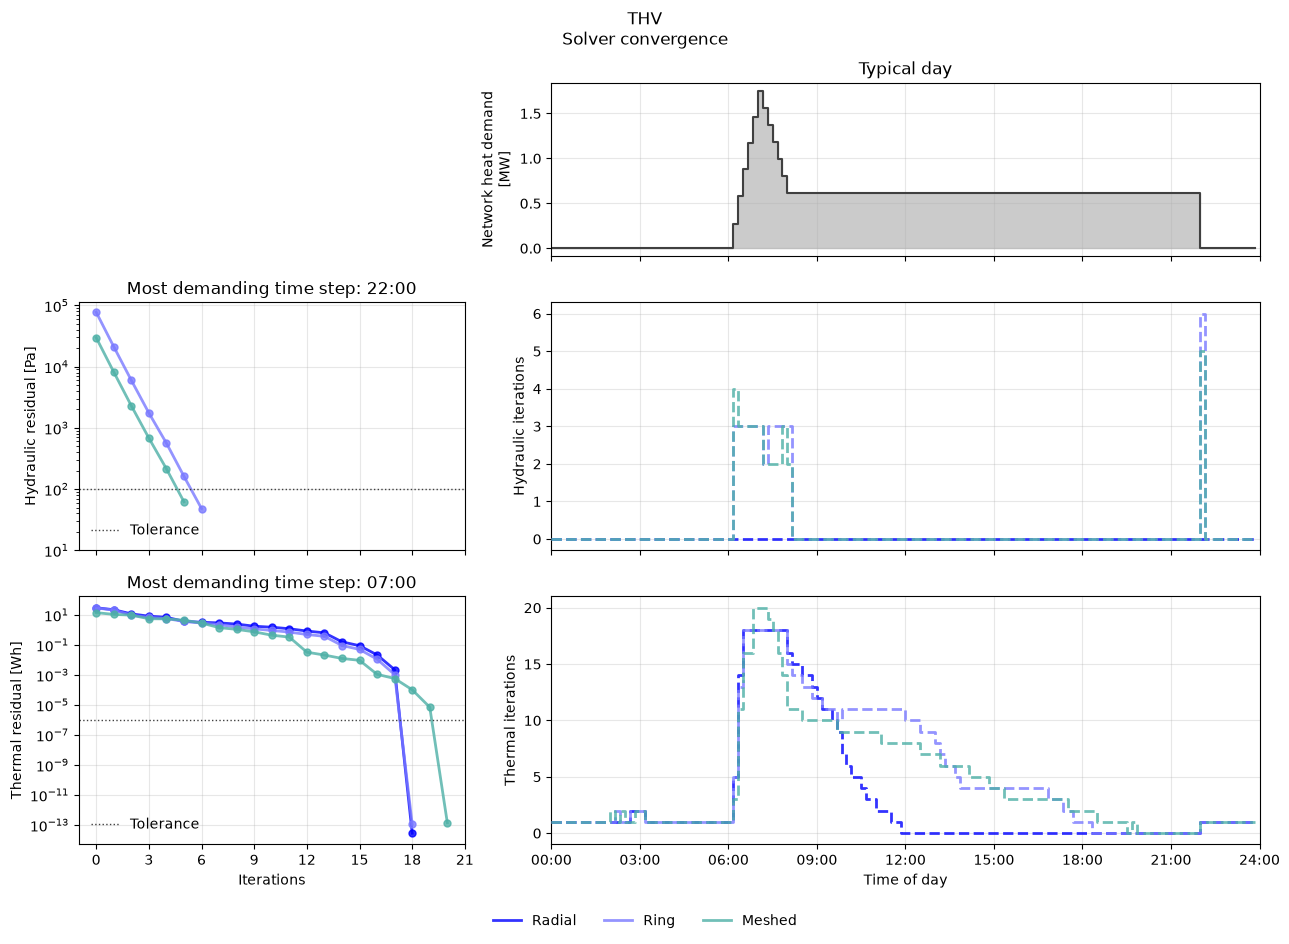

In [45]:
# =============================================================================
# THV — SOLVER CONVERGENCE (convergence trajectories + iterations per time step)
# =============================================================================
THV = list(THV_NETWORKS)
DOMAINS = {"hydraulics": "Hydraulic", "thermal": "Thermal"}
TOL     = {"hydraulics": 1e2, "thermal": 1e-6}                # pydhn error thresholds
RES_UNIT = {"hydraulics": "Pa", "thermal": "Wh"}
TOL_LABEL = {"hydraulics": "Tolerance", "thermal": "Tolerance"}
REF_HOUR = {"hydraulics": None, "thermal": 7.0}

# ---- a. Convergence statistics ---------------------------------------------
rows = {}
for a in THV:
    si = THV_NETWORKS[a]["solver_iteration"]
    for dom, lab in DOMAINS.items():
        rows[(a, lab)] = {
            "mean iterations":     si[f"{dom}_iterations"].mean(),
            "max iterations":      si[f"{dom}_iterations"].max(),
            "non-converged steps": int((~si[f"{dom}_converged"].astype(bool)).sum()),
            "max final residual":  si[f"{dom}_final_residual"].max(),
        }
CONV = pd.DataFrame(rows).T
display(CONV)

# ---- b. Convergence trajectory (left) + iterations on a typical day (right) --
DAY = 2                                                     # Wednesday
STEP_STYLE = {"3G_R_S": dict(ls="--", z=2),
              "3G_L_S": dict(ls="--", z=3),
              "3G_M_S": dict(ls="--", z=4)}
HOUR_TICKS = range(0, 25, 3)

def hhmm(t):
    """Time step index -> 'hh:mm' within the day."""
    m = int(round((t % STEPS_PER_DAY) * STEP_H * 60))
    return f"{m // 60:02d}:{m % 60:02d}"

fig = plt.figure(figsize=(13, 9.5))
gs  = fig.add_gridspec(3, 2, width_ratios=[1.2, 2.2], height_ratios=[0.7, 1, 1])
ax_dem = fig.add_subplot(gs[0, 1])
ax_h   = fig.add_subplot(gs[1, 0])
ax = np.array([[ax_h,                                  fig.add_subplot(gs[1, 1], sharex=ax_dem)],
               [fig.add_subplot(gs[2, 0], sharex=ax_h), fig.add_subplot(gs[2, 1], sharex=ax_dem)]])
fig.add_subplot(gs[0, 0]).axis("off")

# ---- aggregated network heat demand on the typical day ---------------------
dem = day_slice(demand_power(THV[0]), DAY) / 1e6           # same profile for the three THV networks
ax_dem.fill_between((dem.index - dem.index[0]) * STEP_H, dem, step="post", color="#BFBFBF", alpha=LINE_ALPHA)
ax_dem.step((dem.index - dem.index[0]) * STEP_H, dem, where="post", color="#404040", lw=1.5)
ax_dem.set_ylabel("Network heat demand\n"
                  "[MW]"); ax_dem.grid(alpha=0.3)
ax_dem.set_title("Typical day"); ax_dem.tick_params(labelbottom=False)

for k, (dom, lab) in enumerate(DOMAINS.items()):
    # -- left: convergence trajectory of the reference time step
    t_used, direct = [], []
    for a in THV:
        ct = THV_NETWORKS[a]["convergence_traj"]
        ct = ct[ct["domain"] == dom]
        if ct.empty or ct["residual"].max() < 1e-6:
            direct.append(ARCHETYPES[a]["topo"])
            continue
        it_step = ct.groupby("timestep")["iteration"].max()
        if REF_HOUR[dom] is not None:
            at_ref = it_step[np.isclose((it_step.index % STEPS_PER_DAY) * STEP_H, REF_HOUR[dom])]
            if not at_ref.empty:
                it_step = at_ref
        t_hard = it_step.idxmax()
        t_used.append(hhmm(t_hard))
        tr = ct[ct["timestep"] == t_hard]
        ax[k, 0].semilogy(tr["iteration"], tr["residual"].clip(lower=1e-16), "o-", ms=5,
                          lw=LINE_W, alpha=LINE_ALPHA, color=ARCH_COLORS[a])

    ax[k, 0].set_title(f"Most demanding time step: {' / '.join(dict.fromkeys(t_used))}")
    ax[k, 0].axhline(TOL[dom], color="#404040", ls=":", lw=1.0, label=TOL_LABEL[dom])
    ax[k, 0].set_ylim(bottom=min(ax[k, 0].get_ylim()[0], TOL[dom] / 10))   # room for the legend
    ax[k, 0].legend(loc="lower left", frameon=False)
    ax[k, 0].xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax[k, 0].set_ylabel(f"{lab} residual [{RES_UNIT[dom]}]"); ax[k, 0].grid(alpha=0.3, which="major")

    # -- right: iterations per time step on the typical day
    for a in THV:
        d  = day_slice(THV_NETWORKS[a]["solver_iteration"], DAY)
        st = STEP_STYLE[a]
        ax[k, 1].step((d.index - d.index[0]) * STEP_H, d[f"{dom}_iterations"], where="post",
                      color=ARCH_COLORS[a], ls=st["ls"], lw=LINE_W, alpha=LINE_ALPHA, zorder=st["z"])
    ax[k, 1].set_ylabel(f"{lab} iterations")
    ax[k, 1].set_xlim(0, 24)
    ax[k, 1].set_xticks(HOUR_TICKS, [f"{h:02d}:00" for h in HOUR_TICKS])
    ax[k, 1].grid(alpha=0.3)

ax[0, 0].tick_params(labelbottom=False)
ax[1, 0].set_xlabel("Iterations")
ax[0, 1].tick_params(labelbottom=False)
ax[1, 1].set_xlabel("Time of day")

handles = [Line2D([], [], color=ARCH_COLORS[a], lw=LINE_W, alpha=LINE_ALPHA, label=ARCHETYPES[a]["topo"])
           for a in THV]
fig.legend(handles=handles, loc="lower center", bbox_to_anchor=(0.5, 0.0), ncol=len(handles), frameon=False)
fig.suptitle("THV\nSolver convergence"); fig.tight_layout(rect=(0, 0.04, 1, 1))
save_fig(fig, "THV_solver"); plt.show()

[SAVED] output\results\THV_fields.png


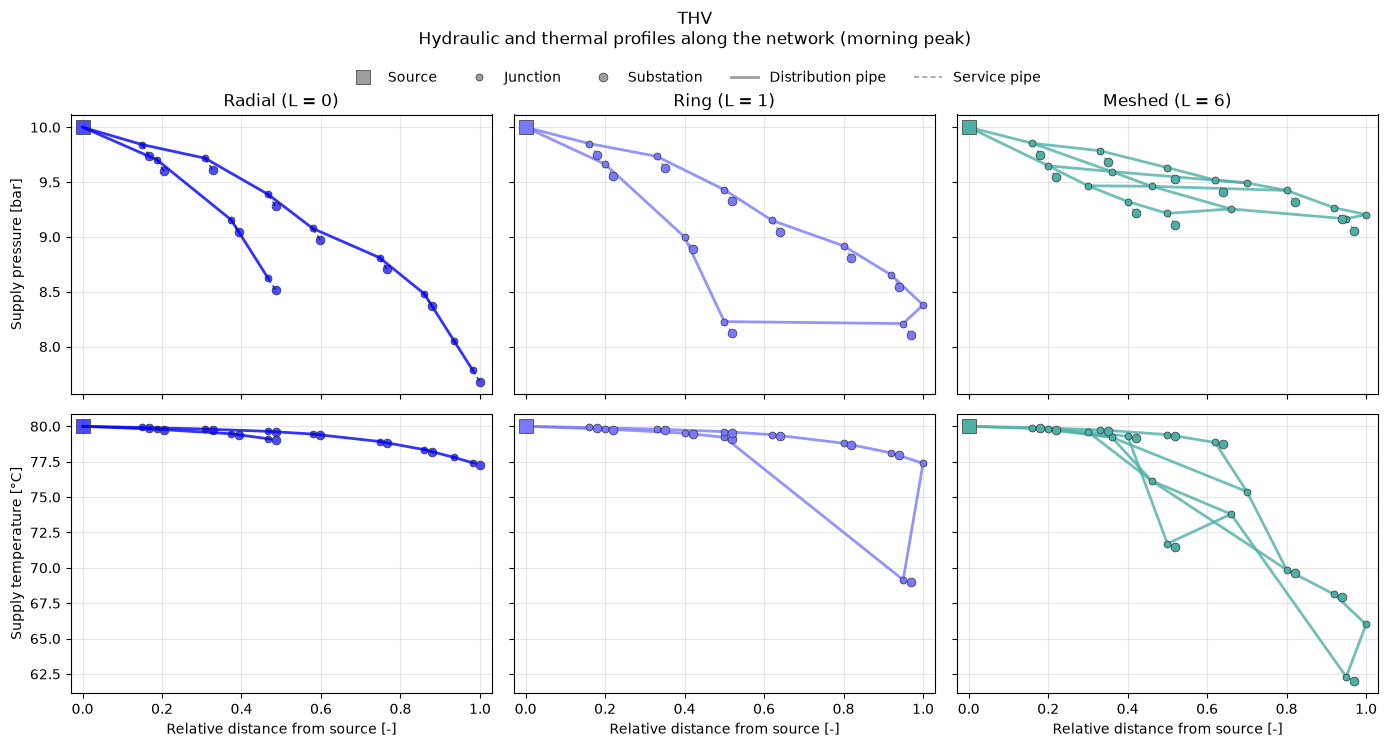

In [46]:
# =============================================================================
# THV — HYDRAULIC AND THERMAL FIELDS (network profiles)
# Every pipe is drawn as a segment between its two end nodes, at their relative network distance
# from the source, preserving the branching. One column per archetype, one row per quantity.
# =============================================================================
THV    = list(THV_NETWORKS)
t_peak = {a: demand_power(a).idxmax() for a in THV}                  # first peak step

NODE_STYLE = {"source":     dict(marker="s", s=100, label="Source"),
              "junction":   dict(marker="o", s=25, label="Junction"),
              "substation": dict(marker="o", s=40, label="Substation")}
SERVICE_STYLE = dict(ls=(0, (3, 2)), lw_factor=0.6)                  # pipes connecting a substation

def node_distance(aid):
    """Network distance of every node from the reference source, normalised by the farthest node [-],
    and the shortest-path predecessor of each node (the tree along which values are accumulated)."""
    G = load_network(aid)[2]
    pred, dist = nx.dijkstra_predecessor_and_distance(G, reference_source(aid), weight="length")
    dmax = max(dist.values())
    return {n: d / dmax for n, d in dist.items()}, {n: p[0] for n, p in pred.items() if p}

def node_pressure(aid, t):
    """Supply pressure [bar] at every node at time t. The source imposes p_pump_set_bar; the supply pipe
    pressure drops are accumulated along the shortest-path tree with the sign of each pipe
    (cumulative sum respecting the branching)."""
    nodes, pipes, G = load_network(aid)
    dps = dict(zip(_pipe_ids(results[aid]["pipe_s_dp_Pa"]), results[aid]["pipe_s_dp_Pa"].loc[t].values))
    dist, pred = node_distance(aid)
    src = reference_source(aid)
    p_s = {src: float(nodes.loc[nodes.node_id.eq(src), "p_pump_set_bar"].iloc[0])}
    for n in sorted(dist, key=dist.get):                    # parents always before children
        if n == src:
            continue
        p    = pred[n]
        pid  = G.edges[p, n]["pid"]
        sign = 1.0 if pipes.at[pid, "from_node"] == p else -1.0
        p_s[n] = p_s[p] - sign * dps[pid] / 1e5
    return p_s

def node_supply_T(aid, steps):
    """Supply temperature [°C] at every node (source, junctions, users), averaged over the given steps."""
    net = results[aid]
    jT  = net["junction_T_degC"].loc[steps].mean()
    T   = {c[:-2]: v for c, v in jT.items() if c.endswith("_s")}
    T.update(user_supply_T(aid).loc[steps].mean().to_dict())
    nodes = load_network(aid)[0]
    for n in nodes.loc[nodes.node_type.eq("source"), "node_id"]:
        T[n] = float(nodes.loc[nodes.node_id.eq(n), "T_supply_set_degC"].iloc[0])
    return T

def draw_profile(ax, aid, value, color):
    """Distribution pipes (solid), service pipes to the substations (dashed, thinner) and nodes by type."""
    nodes, pipes, _ = load_network(aid)
    dist  = node_distance(aid)[0]
    ntype = dict(zip(nodes.node_id, nodes.node_type.where(nodes.node_type.isin(NODE_STYLE), "substation")))
    seg   = lambda r: ((dist[r.from_node], value[r.from_node]), (dist[r.to_node], value[r.to_node]))
    is_service = lambda r: "substation" in (ntype[r.from_node], ntype[r.to_node])
    rows = [r for r in pipes.reset_index().itertuples() if r.from_node in value and r.to_node in value]
    ax.add_collection(LineCollection([seg(r) for r in rows if not is_service(r)], colors=color,
                                     linewidths=LINE_W, alpha=LINE_ALPHA, capstyle="round", zorder=2))
    ax.add_collection(LineCollection([seg(r) for r in rows if is_service(r)], colors=color,
                                     linewidths=LINE_W * SERVICE_STYLE["lw_factor"], linestyles=SERVICE_STYLE["ls"],
                                     alpha=LINE_ALPHA, zorder=2))
    for kind, st in NODE_STYLE.items():
        nn = [n for n in value if n in dist and ntype.get(n) == kind]
        ax.scatter([dist[n] for n in nn], [value[n] for n in nn], s=st["s"], marker=st["marker"],
                   facecolor=color, edgecolor="#333333", linewidths=0.5, zorder=3 + (kind != "junction"))
    ax.autoscale()

ROWS = {"p": "Supply pressure [bar]", "T": "Supply temperature [°C]"}
fig, ax = plt.subplots(len(ROWS), len(THV), figsize=(14, 7.5), sharex=True, sharey="row")
for j, a in enumerate(THV):
    c = ARCH_COLORS[a]
    draw_profile(ax[0, j], a, node_pressure(a, t_peak[a]), c)
    draw_profile(ax[1, j], a, node_supply_T(a, [t_peak[a]]), c)
    ax[0, j].set_title(f"{ARCHETYPES[a]['topo']} (L = {int(KPI.at[a, 'Loops L'])})")
    ax[1, j].set_xlabel("Relative distance from source [-]")
for i, lab in enumerate(ROWS.values()):
    ax[i, 0].set_ylabel(lab)
for a_ in ax.flat:
    a_.set_xlim(-0.03, 1.03); a_.grid(alpha=0.3)

g = "#9E9E9E"
h = [Line2D([], [], ls="none", marker=st["marker"], ms=np.sqrt(st["s"]), mfc=g, mec="#333333", mew=0.5,
            label=st["label"]) for st in NODE_STYLE.values()]
h += [Line2D([], [], color=g, lw=LINE_W, label="Distribution pipe"),
      Line2D([], [], color=g, lw=LINE_W * SERVICE_STYLE["lw_factor"], ls=SERVICE_STYLE["ls"], label="Service pipe")]
fig.legend(handles=h, loc="upper center", bbox_to_anchor=(0.5, 0.925), ncol=len(h), frameon=False)
fig.suptitle("THV\nHydraulic and thermal profiles along the network (morning peak)", y=0.99)
fig.tight_layout(); fig.subplots_adjust(top=0.85)
save_fig(fig, "THV_fields"); plt.show()

TA

[SAVED] output\results\TA_temperature_drop_map.png


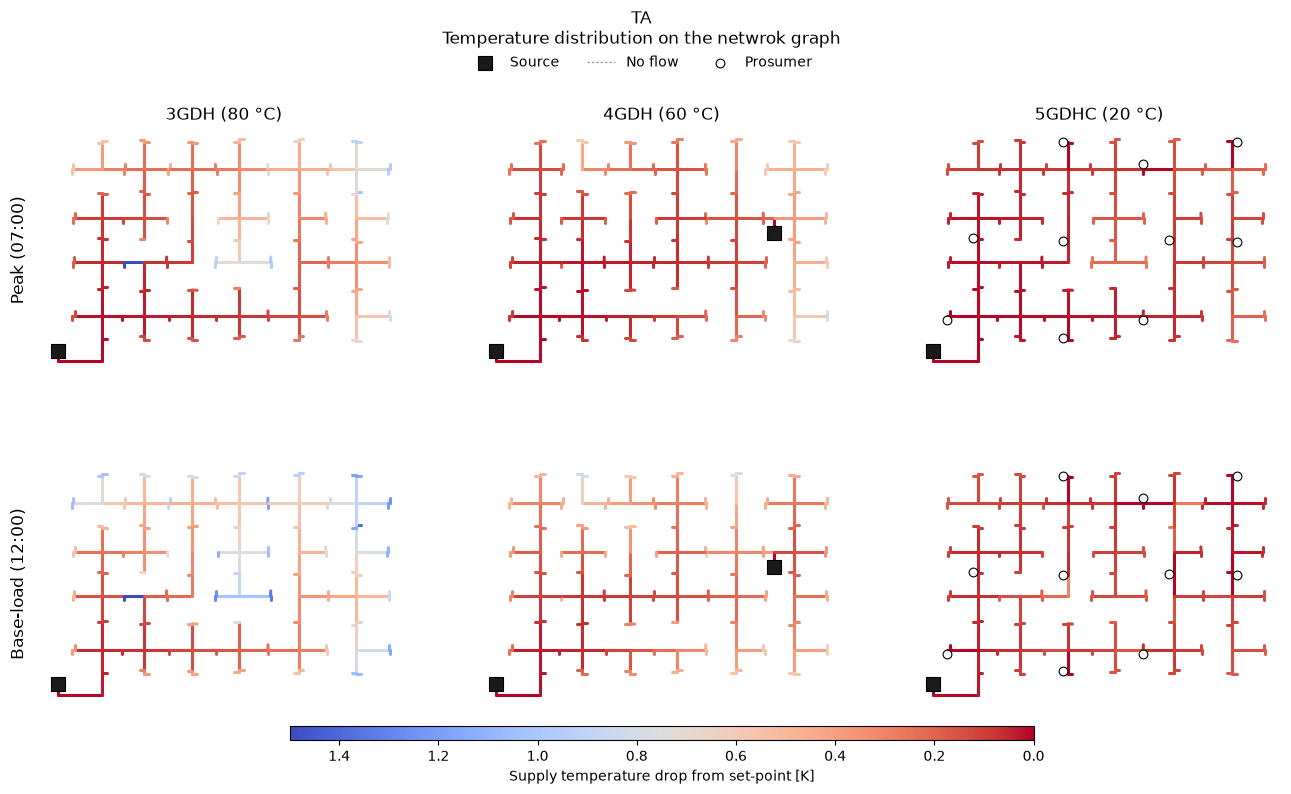

In [47]:
# =============================================================================
# TA — SUPPLY TEMPERATURE DROP FROM SET-POINT ON THE NETWORK GRAPH
# Peak (07:00) and steady state (12:00) of the typical day; same colormap and scale for the
# three generations, so that the thermal degradation of each generation can be compared
# =============================================================================
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

TA        = list(TA_NETWORKS)
DAY       = 2                                               # Wednesday
MAP_HOURS = {"Peak (07:00)": 7, "Base-load (12:00)": 12}
MAP_LW    = 2.2
DROP_CMAP = plt.get_cmap("coolwarm_r")
NO_FLOW   = 1e-3                                            # |mdot| below this = stagnant pipe [kg/s]
Q_RANGE   = 0.02                                            # colour range clipped at 2 % / 98 % of the flowing pipes

SRC_STYLE = {"Source":      dict(marker="s", s=100, fc="#1A1A1A"),
             "Prosumer":    dict(marker="o", s=40, fc="#FFFFFF")}

def t_index(hour):
    """Time-step index of the given hour on the typical day."""
    return DAY * STEPS_PER_DAY + int(round(hour / STEP_H))

def pipe_snapshot(aid, sheet, t):
    """Value of a supply-pipe sheet at time t, indexed by pipe id."""
    df = results[aid][sheet]
    return pd.Series(df.loc[t].values, index=_pipe_ids(df))

def set_point(aid):
    nodes = load_network(aid)[0]
    return float(nodes.loc[nodes.node_type.eq("source"), "T_supply_set_degC"].iloc[0])

def draw_markers(ax, pos, ntype):
    """Sources and prosumers."""
    for k, n in enumerate([n for n, t in ntype.items() if t == "source"]):
        lab = "Source"
        st = SRC_STYLE[lab]
        ax.scatter(*pos[n], marker=st["marker"], s=st["s"], facecolor=st["fc"], edgecolor="k",
                   linewidths=0.8, zorder=6, label=lab)
    pro = [n for n, t in ntype.items() if t == "prosumer"]
    if pro:
        st = SRC_STYLE["Prosumer"]
        ax.scatter([pos[n][0] for n in pro], [pos[n][1] for n in pro], marker=st["marker"], s=st["s"],
                   facecolor=st["fc"], edgecolor="k", linewidths=0.8, zorder=6, label="Prosumer")

def draw_field(ax, aid, values, flowing, colors):
    """Pipes coloured by value (flowing pipes) and dashed grey (stagnant pipes)."""
    pos, ntype, pipes = load_topology(aid)
    pipes = pipes.set_index("pipe_id")
    seg = lambda ids: [(pos[pipes.at[p, "from_node"]], pos[pipes.at[p, "to_node"]]) for p in ids]
    ax.add_collection(LineCollection(seg(values.index[flowing]), colors=colors(values[flowing].values),
                                     linewidths=MAP_LW, capstyle="round", zorder=2))
    if (~flowing).any():
        ax.add_collection(LineCollection(seg(values.index[~flowing]), colors="#9E9E9E", linewidths=0.9,
                                         linestyles=(0, (2, 1.5)), zorder=1, label="No flow"))
    draw_markers(ax, pos, ntype)
    ax.autoscale(); ax.set_aspect("equal"); ax.axis("off")

def map_legend(fig, ax, y=0.94):
    h, l = [], []
    for a_ in ax.flat:
        for hh, ll in zip(*a_.get_legend_handles_labels()):
            if ll not in l: h.append(hh); l.append(ll)
    fig.legend(h, l, loc="upper center", bbox_to_anchor=(0.5, y), ncol=len(l), frameon=False)

def row_labels(ax):
    for i, lab in enumerate(MAP_HOURS):
        ax[i, 0].text(-0.04, 0.5, lab, transform=ax[i, 0].transAxes, rotation=90,
                      ha="right", va="center", fontsize=plt.rcParams["axes.titlesize"])

# ---- fields ------------------------------------------------------------------
T_MAP    = {a: {lab: pipe_snapshot(a, "pipe_s_T_out_degC", t_index(h)) for lab, h in MAP_HOURS.items()} for a in TA}
FLOW_MAP = {a: {lab: pipe_snapshot(a, "pipe_s_mdot_kgs", t_index(h)).abs() > NO_FLOW for lab, h in MAP_HOURS.items()}
            for a in TA}

# ---- figure ------------------------------------------------------------------
DROP = {a: {lab: set_point(a) - T_MAP[a][lab] for lab in MAP_HOURS} for a in TA}
vmax = max(DROP[a][lab][FLOW_MAP[a][lab]].quantile(1 - Q_RANGE) for a in TA for lab in MAP_HOURS)
norm = Normalize(0, np.ceil(vmax * 2) / 2)

fig, ax = plt.subplots(len(MAP_HOURS), len(TA), figsize=(16, 8.5))
for j, a in enumerate(TA):
    for i, lab in enumerate(MAP_HOURS):
        draw_field(ax[i, j], a, DROP[a][lab], FLOW_MAP[a][lab], lambda v: DROP_CMAP(norm(v)))
    ax[0, j].set_title(f"{ARCHETYPES[a]['gen']} ({set_point(a):.0f} °C)")
cb = fig.colorbar(ScalarMappable(norm=norm, cmap=DROP_CMAP), ax=ax, orientation="horizontal",
                  fraction=0.035, pad=0.03, aspect=50, shrink=0.6)
cb.set_label("Supply temperature drop from set-point [K]"); cb.ax.invert_xaxis()
row_labels(ax); map_legend(fig, ax)
fig.suptitle("TA\nTemperature distribution on the netwrok graph")
save_fig(fig, "TA_temperature_drop_map"); plt.show()

CS

,Users,Nodes,Pipes,Loops L,Pipe length [km],Wall-clock time [s],Time per step [s],Time per step per pipe [ms]
3G_R_S,10.0,22.0,21.0,0.0,1.750,157.03,0.156,7.418
3G_L_S,10.0,22.0,22.0,1.0,2.200,248.62,0.247,11.211
3G_M_S,10.0,27.0,32.0,6.0,3.700,309.00,0.307,9.580
3G_M_M,100.0,221.0,224.0,4.0,8.613,5165.50,5.125,22.877
3G_M_L,400.0,931.0,944.0,14.0,62.680,22797.66,22.617,23.958


[SAVED] output\results\CS_scalability.png


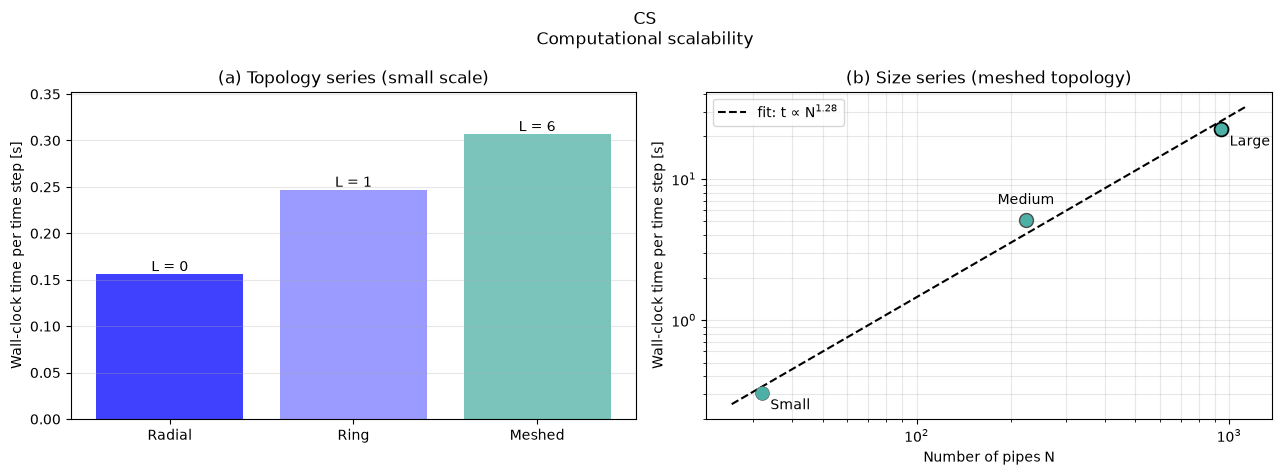

Scaling exponent (time per step vs number of pipes): 1.28


In [48]:
# =============================================================================
# CS — COMPUTATIONAL SCALABILITY
# Wall-clock time of the full simulation (pre-heating excluded)
# =============================================================================
SIM_TIME_S = {               # [s]
    "3G_R_S":   157.03,
    "3G_L_S":   248.62,
    "3G_M_S":   309.00,
    "3G_M_M":   5165.50,
    "3G_M_L":   22797.66,
}
N_STEPS = 1008

CS = list(CS_NETWORKS)
size = pd.DataFrame({a: {"Users": KPI.at[a, "Users"],
                         "Nodes": len(load_network(a)[0]),
                         "Pipes": len(load_network(a)[1]),
                         "Loops L": KPI.at[a, "Loops L"],
                         "Pipe length [km]": KPI.at[a, "Pipe length [km]"]} for a in CS}).T
size["Wall-clock time [s]"] = [SIM_TIME_S.get(a, np.nan) for a in CS]
size["Time per step [s]"]   = size["Wall-clock time [s]"] / N_STEPS
size["Time per step per pipe [ms]"] = 1e3 * size["Time per step [s]"] / size["Pipes"]
display(size.round(3))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
# ---- a. Topology series (small scale) -------------------------------------
topo = [a for a in CS_SERIES["topology"] if a in CS]
ax[0].bar(range(len(topo)), size.loc[topo, "Time per step [s]"], color=[ARCH_COLORS[a] for a in topo], alpha=0.75, **arch_edges(topo))
for i, a in enumerate(topo):
    ax[0].text(i, size.at[a, "Time per step [s]"], f"L = {int(size.at[a, 'Loops L'])}", ha="center", va="bottom")
ax[0].set_xticks(range(len(topo)), [ARCHETYPES[a]["topo"] for a in topo])
ax[0].set_ylabel("Wall-clock time per time step [s]"); ax[0].margins(y=0.15)
ax[0].set_title("(a) Topology series (small scale)"); ax[0].grid(alpha=0.3, axis="y")

# ---- b. Size series (meshed topology), log–log with power-law fit --------
LABEL_OFFSET = {"Small": (6, -12), "Medium": (0, 9), "Large": (6, -12)}   # [pt] from the marker centre

sz = [a for a in CS_SERIES["size"] if a in CS]
n_p, t_s = size.loc[sz, "Pipes"].values.astype(float), size.loc[sz, "Time per step [s]"].values
b, log_c = np.polyfit(np.log(n_p), np.log(t_s), 1)
for a, xx, yy in zip(sz, n_p, t_s):
    ax[1].scatter(xx, yy, s=100, color=ARCH_COLORS[a], zorder=3, **arch_marker_edge(a))
for a, xx, yy in zip(sz, n_p, t_s):
    sc = ARCHETYPES[a]["scale"]
    dx, dy = LABEL_OFFSET[sc]
    ax[1].annotate(sc, (xx, yy), xytext=(dx, dy), textcoords="offset points",
                   ha="center" if sc == "Medium" else "left", va="bottom" if dy > 0 else "baseline")
xf = np.logspace(np.log10(n_p.min() * 0.8), np.log10(n_p.max() * 1.2), 50)
ax[1].loglog(xf, np.exp(log_c) * xf**b, "--", color="black", label=f"fit: t ∝ N$^{{{b:.2f}}}$")
ax[1].set_xlabel("Number of pipes N"); ax[1].set_ylabel("Wall-clock time per time step [s]")
ax[1].set_title("(b) Size series (meshed topology)"); ax[1].legend(); ax[1].grid(alpha=0.3, which="both")
fig.suptitle("CS\nComputational scalability"); fig.tight_layout()
save_fig(fig, "CS_scalability"); plt.show()
print(f"Scaling exponent (time per step vs number of pipes): {b:.2f}")